## APPLICABILITY DOMAIN

This a very important stage of our QSAR model, So even a good QSAR model isn't reliable if it falls outside Applicability domain. So we use test compound(Eugenol) to determine AD.

In [10]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 19.9 MB/s eta 0:00:00


In [7]:
#@title File I/O configuration

import os

#Modify the path to indicate the folder where all files will be stored,
#and uncomment the following line if you have uploaded your file directly
#PATH = "/content/"

# If you are using Google Drive, uncomment the following lines:
from google.colab import drive
drive.mount('/content/drive')
PATH = "/content/drive/MyDrive/"


Mounted at /content/drive


## PART 7: Prediction and applicability domain

In this lesson, we will learn how to make a prediction with our optimised model, and we will use different methods to assess whether the predicted substance is within the chemical space of the model, i.e. its applicability domain.

The notebook is divided into several steps:

* Read an optimised model
* Perform a prediction for an example molecule
* Explore different methods to assess the applicability domain and apply them to the example molecule

First of all, however, we need to train the model that will be used later for prediction.

To do this, import the necessary modules and create an estimator using the chosen algorithm and hyperparameters from the previous notebook.

First, use the next cell to load the necessary files.

In [8]:
#@title Train the model
import pandas as pd
from sklearn.linear_model import LinearRegression

# Define paths using the active PATH variable
train_filepath = os.path.join(PATH, 'QSAR_Models', 'RAT_LC50_Train_RFE_linreg.csv')

# Load the training dataset
train_data = pd.read_csv(train_filepath, sep=';')

# Separate the features (descriptors) and target variable (y)
X_train = train_data.iloc[:, 2:]
y_train = train_data['y']

# Instantiate the selected estimator (Linear Regression)
model = LinearRegression()

# Fit the model using only the training set
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


### Prediction of eugenol activity towards rat LC₅₀ toxicity  

Let us start with eugenol. Your first task is to obtain the SMILES of eugenol by searching in some of the databases and/or tools discussed during the course.

Write code below to visualise the molecule from the SMILES using RDKit, by creating a `Mol` object.

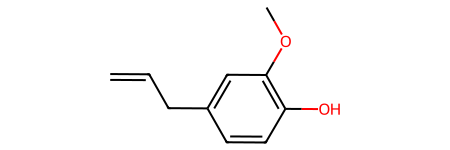

In [11]:
#@title Visualise the molecule from the SMILES
#Import the Chem module from rdkit
from rdkit import Chem
from rdkit.Chem import Draw

#Transform the eugenol SMILES into a Mol object
eugenol_smiles = "C1=CC(=C(C=C1CC=C)OC)O" # Standard SMILES for Eugenol
mol = Chem.MolFromSmiles(eugenol_smiles)

#Visualise the Mol object
mol

The next step is to calculate the descriptors by revisiting what you did in the previous Jupyter Notebook. In this case, you do not need to calculate all the descriptors, but only those that you are using in your model. However, it is easier to calculate all of them and then filter the appropriate columns.

To simplify this process, you can reuse the code from the previous Jupyter Notebook to calculate all the descriptors and save them in a DataFrame. The steps are:

* The code used in the previous Jupyter Notebook uses a DataFrame to introduce the SMILES list, so you need to create a DataFrame with the `SMILES` column
* Calculate the RDKit descriptors and include them in the same DataFrame
* Select only the columns corresponding to the selected descriptors and save them in a different DataFrame called `X_eug`

Finally, you should obtain an `X_eug` DataFrame containing only the descriptor columns. You can obtain these columns from `X_train` or `X_test`. Note that the order of the columns is important, as the code for generating the model and making predictions will not read the column names, but will assume that they are in the correct order.

In [13]:
#@title Calculate the descriptors for eugenol
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors, Descriptors

# Fix NameError: Use eugenol_smiles defined in the previous cell
df_eug = pd.DataFrame([eugenol_smiles], columns=['SMILES'])

descriptors_list = []

descriptors_rdkit = Descriptors.CalcMolDescriptors(mol)

descriptors_list.append(descriptors_rdkit)

df_eugenol_with_descriptors = pd.concat([df_eug[['SMILES']], pd.DataFrame(descriptors_list)], axis=1)


df_LC50_final = df_eugenol_with_descriptors.copy()

# Load using the defined PATH directory to prevent FileNotFoundError
train_database = pd.read_csv(os.path.join(PATH, 'QSAR_Models', 'RAT_LC50_Train_RFE_linreg.csv'), sep=';')

X_train = train_database.iloc[:,2:]

X_eug = df_LC50_final[X_train.columns]


# Keep this to visualise your calculated descriptors
X_eug

,BalabanJ,PEOE_VSA9,TPSA,FractionCSP3,fr_ether
0,2.95956,7.109798,29.46,0.2,1


Check the descriptor values obtained for your target molecule in the DataFrame above. In some cases, descriptor calculation can produce non-numerical values that are not useful, such as computation errors or a lack of parameters for particular elements. If you have values such as `True` and `False`, this is not an issue, as these are binary variables that are printed in this visual way, but the model can use them by interpreting them as 1 and 0.

For the sake of simplicity, we are not taking this into account here. However, the presence of non-numerical values, particularly if they represent a significant percentage, is an indication of a poor-quality prediction and may imply that we cannot use this molecule in our model. As we did with the full dataset, we can avoid this issue with a KNN imputer that uses the mean of the values of a few neighbours from the full original dataset.

In fact, because we trained the model with an imputed and standardised version of the descriptors, we need to follow the same procedure instead of using the unprocessed descriptors.

Therefore, to be able to calculate a prediction, we need to check the descriptors for the prediction, fill the gaps, and standardise them using the same method. To start this process, we need to recover the descriptor values obtained for the training dataset, which were stored in a `.csv` file after splitting. Open the `.csv` file containing the descriptors obtained before imputation and standardisation for the training file in a DataFrame, and filter it so that it contains only the columns corresponding to the descriptors selected for the model we are going to use. Call it `database_reduced`.

First, however, you should upload the file `RAT_LC50_Train.csv` to the server.

In [14]:
#@title Create a reduced version of the training set
import pandas as pd
import os

# Import the unscaled training set as a DataFrame
# The instructions mention RAT_LC50_Train.csv which contains the raw/unscaled descriptors
train_csv_path = os.path.join(PATH, 'QSAR_Models', 'RAT_LC50_Train.csv')
original_train = pd.read_csv(train_csv_path, sep=';')

# Create a reduced DataFrame using only the descriptors used in the model as columns
descriptor_cols = list(X_eug.columns)  # BalabanJ, PEOE_VSA9, TPSA, FractionCSP3, fr_ether
database_reduced = original_train[descriptor_cols]

# Print the columns to check your work
print("Columns in database_reduced:", list(database_reduced.columns))
display(database_reduced.head())

Columns in database_reduced: ['BalabanJ', 'PEOE_VSA9', 'TPSA', 'FractionCSP3', 'fr_ether']


,BalabanJ,PEOE_VSA9,TPSA,FractionCSP3,fr_ether
0,3.023716,0.0,0.00,1.000000,0.0
1,3.541197,0.0,0.00,1.000000,0.0
2,5.158825,0.0,17.07,0.750000,0.0
3,6.235714,0.0,0.00,1.000000,0.0
4,5.891780,0.0,74.60,0.666667,0.0


Check the descriptor values obtained for your target molecule. In some cases, descriptor calculation can produce non-numerical values that are not useful, such as computation errors or a lack of parameters for particular elements. If you have values such as `True` and `False`, this is not an issue, as these are binary variables that are printed in this visual way, but the model can use them by interpreting them as 1 and 0.

For the sake of simplicity, we are not taking this into account here. However, the presence of non-numerical values, particularly if they represent a significant percentage, is an indication of a poor-quality prediction and may imply that we cannot use this molecule in our model. As we did with the full dataset, we can avoid this issue with a KNN imputer that uses the mean of the values of a few neighbours from the full original dataset.

Furthermore, we need to repeat the standardisation of the descriptors with the original dataset, as we did earlier, but in this case we need to restrict the scaler to the descriptors that we are going to rescale, by using the `database_reduced` DataFrame.

In the following cell, you can use the `imputer_scaler` function, similar to the one previously defined in Lesson 2.5, to perform the imputation and scaling of one or more target molecules.

In [16]:
#@title Imputation and standardisation

from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler


def imputer_scaler(df_target, df_reference):
    # Prepare the imputer and scaler objects
    imputer = KNNImputer(missing_values=np.nan, n_neighbors=3, weights="uniform")
    scaler = StandardScaler()

    columns_descriptors = list(df_reference.columns)

    reference_descriptors_matrix = df_reference[columns_descriptors]

    imputer.fit(reference_descriptors_matrix)

    target_descriptors_matrix = df_target[columns_descriptors]

    imputed_ref_matrix = imputer.transform(reference_descriptors_matrix)
    imputed_matrix = imputer.transform(target_descriptors_matrix)
    scaler.fit(imputed_ref_matrix)

    imputed_scaled_matrix = scaler.transform(imputed_matrix)
    df_imputed_scaled = pd.DataFrame(imputed_scaled_matrix, columns = columns_descriptors)




    return df_imputed_scaled


Now, apply the function defined above to our current problem.

In [17]:
#@title Apply the function
import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

# Defining the helper function to make sure it is in the current namespace
def imputer_scaler(df_target, df_reference, list_descriptors):
    imputer = KNNImputer(missing_values=np.nan, n_neighbors=3, weights="uniform")
    scaler = StandardScaler()

    reference_descriptors_matrix = df_reference[list_descriptors]
    imputer.fit(reference_descriptors_matrix)

    target_descriptors_matrix = df_target[list_descriptors]
    imputed_matrix = imputer.transform(target_descriptors_matrix)

    # Fit the scaler using the imputed reference matrix
    imputed_ref_matrix = imputer.transform(reference_descriptors_matrix)
    scaler.fit(imputed_ref_matrix)

    imputed_scaled_matrix = scaler.transform(imputed_matrix)
    df_imputed_scaled = pd.DataFrame(imputed_scaled_matrix, columns=list_descriptors)

    return df_imputed_scaled

# Applying the function to obtain X_eug_scaled
descriptor_cols = list(database_reduced.columns)
X_eug_scaled = imputer_scaler(X_eug, database_reduced, descriptor_cols)

# Display the scaled descriptors to verify the result
X_eug_scaled

,BalabanJ,PEOE_VSA9,TPSA,FractionCSP3,fr_ether
0,-1.508468,1.57635,0.717679,-1.934731,1.564925


After running your code to fit and check your model, making a prediction is done in the same way as we did to assess the training and test sets.

Note that the result will be a list of all the predictions, even if only one prediction is made. What is the prediction for eugenol?

In [18]:
#@title Eugenol prediction

# Use the generated model to predict the value for eugenol
eugenol_pred = model.predict(X_eug_scaled)

# Print the prediction to see the result
print(f"Predicted rat LC50 toxicity for Eugenol: {eugenol_pred[0]:.4f}")

Predicted rat LC50 toxicity for Eugenol: 5.5482


### Section 2: Applicability domain of eugenol in the rat LC₅₀ toxicity model

A prediction has been made, but can we trust it? In addition to assessing the quality of the model, we need to check whether the molecule we are testing is within the chemical space considered by our model. To do this, we measure the applicability domain. There are several methods for doing so, such as leverage, Euclidean distance, Tanimoto similarity, and kernel density estimation.

#### Tanimoto index

The Tanimoto index is a measure of molecular similarity based on fingerprints, so the first thing we need is a fingerprint. A fingerprint is an identifier formed by a binary string that shows the presence or absence of certain groups or features in molecules. There is not a single set of features and, therefore, there are several fingerprints that can be used. We are going to use the MACCS keys fingerprint. This can be calculated using the rdMolDescriptors module from RDKit. You can check the documentation [here](https://www.rdkit.org/docs/source/rdkit.Chem.rdMolDescriptors.html).

Obtain it for eugenol.


In [19]:
#@title Obtain the eugenol fingerprint
# Import the rdMolDescriptors module from rdkit.Chem
from rdkit.Chem import rdMolDescriptors

# Obtain the fingerprint using the GetMACCSKeysFingerprint function
eugenol_fp = rdMolDescriptors.GetMACCSKeysFingerprint(mol)

# Convert fingerprint to list and print results to inspect
eugenol_fp_list = list(eugenol_fp)
print("Eugenol MACCS Fingerprint (as list):", eugenol_fp_list)
print("Sum of active bits (values of 1) in Eugenol fingerprint:", sum(eugenol_fp_list))

Eugenol MACCS Fingerprint (as list): [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0]
Sum of active bits (values of 1) in Eugenol fingerprint: 20


### **Q1.** What is the sum of the values in the eugenol fingerprint?

Now we need to compare this fingerprint with our training dataset. We are going to use the Jaccard-Tanimoto coefficient for similarity, which is calculated as:

$$S_{J-T} = \frac{P_{both}}{P_{both}+P_{1}+P_{2}}$$

where $P$ refers to the number of features that are positive in both fingerprints, only in the first fingerprint, and only in the second fingerprint (${P_{both}}$, $P_{1}$, and $P_{2}$, respectively).

As a test, let us calculate the similarity index of caffeine with butyric acid and nicotine using the formula above. Note that the easiest way to operate with the 0s and 1s of the fingerprint is to convert it into a list first.



In [20]:
#@title Calculate the Jaccard-Tanimoto similarity index
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors

# Look for the butyric acid SMILES and obtain its fingerprint
butyric_acid_smiles = "CCCC(=O)O"
butyric_acid_mol = Chem.MolFromSmiles(butyric_acid_smiles)
butyric_acid_fp = rdMolDescriptors.GetMACCSKeysFingerprint(butyric_acid_mol)

# Look for the nicotine SMILES and obtain its fingerprint
nicotine_smiles = "CN1CCCC1C2=CN=CC=C2"
nicotine_mol = Chem.MolFromSmiles(nicotine_smiles)
nicotine_fp = rdMolDescriptors.GetMACCSKeysFingerprint(nicotine_mol)

# Convert the three fingerprints into lists: butyric acid, nicotine, and eugenol
butyric_acid_fp_list = list(butyric_acid_fp)
nicotine_fp_list = list(nicotine_fp)
eugenol_fp_list = list(eugenol_fp)

def calculate_tanimoto(fp_list1, fp_list2):
    both = 0
    only1 = 0
    only2 = 0
    for bit1, bit2 in zip(fp_list1, fp_list2):
        if bit1 == 1 and bit2 == 1:
            both += 1
        elif bit1 == 1:
            only1 += 1
        elif bit2 == 1:
            only2 += 1
    return both / (both + only1 + only2) if (both + only1 + only2) > 0 else 0.0

# Calculate the similarity index between eugenol and nicotine
sim_nicotine = calculate_tanimoto(eugenol_fp_list, nicotine_fp_list)

# Repeat the process for the comparison with butyric acid
sim_butyric = calculate_tanimoto(eugenol_fp_list, butyric_acid_fp_list)

# Print the similarity indexes
print(f"Jaccard-Tanimoto similarity between Eugenol and Nicotine: {sim_nicotine:.4f}")
print(f"Jaccard-Tanimoto similarity between Eugenol and Butyric Acid: {sim_butyric:.4f}")

Jaccard-Tanimoto similarity between Eugenol and Nicotine: 0.1277
Jaccard-Tanimoto similarity between Eugenol and Butyric Acid: 0.2069


### **Q2.** What is the similarity index for butyric acid?

We need to do this for each molecule in our training dataset. For each one, we will obtain the fingerprint and calculate the index. However, for eugenol to fall within our applicability domain, it needs to be similar to at least one of our molecules, so we only need to focus on the most similar one. Therefore, we do not need to store all the values, but only to keep track of the maximum value and provide it at the end.

In [21]:
#@title Check the maximum similarity between eugenol and the training dataset
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors
import pandas as pd
import os

# Obtain the eugenol fingerprint
eugenol_smiles = "C1=CC(=C(C=C1CC=C)OC)O"
eugenol_mol = Chem.MolFromSmiles(eugenol_smiles)
eugenol_fp = rdMolDescriptors.GetMACCSKeysFingerprint(eugenol_mol)
eugenol_fp_list = list(eugenol_fp)

# Read the training dataset
train_filepath = os.path.join(PATH, 'QSAR_Models', 'RAT_LC50_Train_RFE_linreg.csv')
train_data_ad = pd.read_csv(train_filepath, sep=';')

# Extract the SMILES from the training dataset
train_smiles_list = train_data_ad['SMILES'].tolist()

# Set the current maximum similarity to 0
max_similarity = 0.0
most_similar_smiles = ""

def calculate_tanimoto(fp_list1, fp_list2):
    both = sum(1 for b1, b2 in zip(fp_list1, fp_list2) if b1 == 1 and b2 == 1)
    sum_fps = sum(fp_list1) + sum(fp_list2)
    return both / (sum_fps - both) if (sum_fps - both) > 0 else 0.0

# Create a for loop through all the SMILES from the training dataset
for smiles in train_smiles_list:
    try:
        mol_train = Chem.MolFromSmiles(smiles)
        if mol_train is not None:
            fp_train = rdMolDescriptors.GetMACCSKeysFingerprint(mol_train)
            fp_train_list = list(fp_train)

            # Calculate similarity score
            similarity = calculate_tanimoto(eugenol_fp_list, fp_train_list)

            # Check if greater than current maximum
            if similarity > max_similarity:
                max_similarity = similarity
                most_similar_smiles = smiles
    except Exception as e:
        continue

# Print the maximum similarity value between eugenol and the training dataset
print(f"Maximum Jaccard-Tanimoto similarity: {max_similarity:.4f}")
print(f"Most similar compound in training set: {most_similar_smiles}")

Maximum Jaccard-Tanimoto similarity: 0.3462
Most similar compound in training set: O=C(O)c1c(F)c(F)c(F)c(F)c1F


The similarity value that is included within the applicability domain depends on the fingerprint used. For example, for MACCS keys fingerprints, an acceptable value is 0.573, which corresponds to more than 95% similarity.

More information can be found [here](http://rdkit.blogspot.com/2013/10/fingerprint-thresholds.html).

### **Q3.** Is eugenol inside the applicability domain of our model?

Because the other methods for calculating the applicability domain have been explained in the previous module, we are going to use only the Jaccard-Tanimoto similarity index in the current work.

# Exercise with multiple molecules

Predict the toxicity of the following molecules using the rat LC₅₀ toxicity model, and indicate whether they are within the applicability domain using the Jaccard-Tanimoto similarity index.
 * Citric Acid
 * Stearic acid
 * Sucrose
 * Dimethoxydimethylsilane
 * 1-methoxy-2-propanol



To help with the following steps, we are going to include here the function to calculate the metrics of a regression model and the function to impute and scale the descriptor values introduced in the previous notebook.

In [28]:
#@title Function to check regression models

def check_regression_model(model,train_file,test_file,name,save=True):
    from sklearn.model_selection import cross_validate
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score
    #First, open the training and test files and save the DataFrames with the descriptors and endpoint values
    train_dataset = pd.read_csv(train_file,sep=';')
    X_train = train_dataset.iloc[:, 2:]
    Y_train = train_dataset["y"]

    test_dataset = pd.read_csv(test_file,sep=';')
    X_test = test_dataset.iloc[:, 2:]
    Y_test = test_dataset["y"]

    #Fit the model using only the training data
    model.fit(X_train,Y_train)

    #Predict the training data and calculate the metrics
    Y_train_pred = model.predict(X_train)
    tr_R2=round(r2_score(Y_train,Y_train_pred),3)
    tr_mae=round(mean_absolute_error(Y_train,Y_train_pred),3)
    tr_mse=round(mean_squared_error(Y_train,Y_train_pred),3)
    tr_ev=round(explained_variance_score(Y_train,Y_train_pred),3)

    #Predict the test data and calculate the metrics
    Y_test_pred = model.predict(X_test)
    ts_R2=round(r2_score(Y_test,Y_test_pred),3)
    ts_mae=round(mean_absolute_error(Y_test,Y_test_pred),3)
    ts_mse=round(mean_squared_error(Y_test,Y_test_pred),3)
    ts_ev=round(explained_variance_score(Y_test,Y_test_pred),3)

    #Perform cross-validation and save only the test R-square value
    cv_results = cross_validate(model, X_train, Y_train,scoring='r2',return_train_score=True)
    cv_R2_mean=round(cv_results['test_score'].mean(),3)
    cv_R2_dev=round(cv_results['test_score'].std(),3)

    if save:
      results={}
      results.update({name:[tr_R2,tr_mae,tr_mse,tr_ev,
            ts_R2,ts_mae,ts_mse,ts_ev,
            cv_R2_mean,cv_R2_dev]})

    #Print the results
    print('\t\tTRAIN\t\t\t\tTEST')
    print('R squared:\t',tr_R2,'\t\t\t\t',ts_R2)
    print('mae:\t',tr_mae,'\t\t\t\t',ts_mae)
    print('mse:\t',tr_mse,'\t\t\t\t',ts_mse)
    print('ev:\t',tr_ev,'\t\t\t\t',ts_ev)
    print('Cross validation R squared:',cv_R2_mean,'+/-',cv_R2_dev)

    return [tr_R2,tr_mae,tr_mse,tr_ev,
            ts_R2,ts_mae,ts_mse,ts_ev,
            cv_R2_mean,cv_R2_dev]






In [29]:
#@title Function to impute and scale the descriptors


import pandas as pd
import numpy as np
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

def imputer_scaler(df_target, df_reference, list_descriptors):

    imputer = KNNImputer(missing_values=np.nan, n_neighbors=3, weights="uniform")
    scaler = StandardScaler()

    smiles_target = list(df_target['SMILES'])

    reference_descriptors_matrix = df_reference[list_descriptors]

    imputer.fit(reference_descriptors_matrix)

    target_descriptors_matrix = df_target[list_descriptors]

    imputed_matrix = imputer.transform(target_descriptors_matrix)

    scaler.fit(imputed_matrix)

    imputed_scaled_matrix = scaler.transform(imputed_matrix)

    df_imputed_scaled = pd.DataFrame(imputed_scaled_matrix, columns = list_descriptors)


    df_imputed_scaled.insert(0,'SMILES',smiles_target)

    return df_imputed_scaled

 ## Step 1: Obtain the SMILES of the compounds to analyse and generate a DataFrame with a single column (`SMILES`) containing them.

In [30]:
#@title Create the DataFrame with the SMILES
import pandas as pd

# Dictionary of the compound names and their corresponding canonical SMILES
molecules_data = {
    "Compound_Name": [
        "Citric Acid",
        "Stearic acid",
        "Sucrose",
        "Dimethoxydimethylsilane",
        "1-methoxy-2-propanol"
    ],
    "SMILES": [
        "OC(=O)CC(O)(CC(=O)O)C(=O)O",                 # Citric Acid
        "CCCCCCCCCCCCCCCCCC(=O)O",                     # Stearic acid
        "C(C1C(C(C(O1)OC2(C(C(C(O2)CO)O)O)CO)O)O)O",    # Sucrose
        "CO[Si](C)(C)OC",                             # Dimethoxydimethylsilane
        "CC(CO)OC"                                    # 1-methoxy-2-propanol
    ]
}

# Generate the DataFrame with a single column ('SMILES')
df_multiple = pd.DataFrame(molecules_data)[['SMILES']]

# Display the DataFrame to check your work
df_multiple

,SMILES
0,OC(=O)CC(O)(CC(=O)O)C(=O)O
1,CCCCCCCCCCCCCCCCCC(=O)O
2,C(C1C(C(C(O1)OC2(C(C(C(O2)CO)O)O)CO)O)O)O
3,CO[Si](C)(C)OC
4,CC(CO)OC


## Step 2: Check the model:
  - Regenerate the model
  - Recover the list of selected descriptors as `sel_descriptors`



In [24]:
#@title Regenerate and check the model metrics
import pandas as pd
import os
from sklearn.linear_model import LinearRegression

# Define the check_regression_model function directly to avoid NameError
def check_regression_model(model, train_file, test_file, name, save=True):
    from sklearn.model_selection import cross_validate
    from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, explained_variance_score

    # Open the training and test files
    train_dataset = pd.read_csv(train_file, sep=';')
    X_train = train_dataset.iloc[:, 2:]
    Y_train = train_dataset["y"]

    test_dataset = pd.read_csv(test_file, sep=';')
    X_test = test_dataset.iloc[:, 2:]
    Y_test = test_dataset["y"]

    # Fit the model
    model.fit(X_train, Y_train)

    # Predict training data
    Y_train_pred = model.predict(X_train)
    tr_R2 = round(r2_score(Y_train, Y_train_pred), 3)
    tr_mae = round(mean_absolute_error(Y_train, Y_train_pred), 3)
    tr_mse = round(mean_squared_error(Y_train, Y_train_pred), 3)
    tr_ev = round(explained_variance_score(Y_train, Y_train_pred), 3)

    # Predict test data
    Y_test_pred = model.predict(X_test)
    ts_R2 = round(r2_score(Y_test, Y_test_pred), 3)
    ts_mae = round(mean_absolute_error(Y_test, Y_test_pred), 3)
    ts_mse = round(mean_squared_error(Y_test, Y_test_pred), 3)
    ts_ev = round(explained_variance_score(Y_test, Y_test_pred), 3)

    # Cross-validation
    cv_results = cross_validate(model, X_train, Y_train, scoring='r2', return_train_score=True)
    cv_R2_mean = round(cv_results['test_score'].mean(), 3)
    cv_R2_dev = round(cv_results['test_score'].std(), 3)

    # Print the results
    print('\t\tTRAIN\t\t\t\tTEST')
    print('R squared:\t', tr_R2, '\t\t\t\t', ts_R2)
    print('mae:\t', tr_mae, '\t\t\t\t', ts_mae)
    print('mse:\t', tr_mse, '\t\t\t\t', ts_mse)
    print('ev:\t', tr_ev, '\t\t\t\t', ts_ev)
    print('Cross validation R squared:', cv_R2_mean, '+/-', cv_R2_dev)

    return [tr_R2, tr_mae, tr_mse, tr_ev,
            ts_R2, ts_mae, ts_mse, ts_ev,
            cv_R2_mean, cv_R2_dev]

# Define the paths for the training and test files using the active PATH variable
train_filepath = os.path.join(PATH, 'QSAR_Models', 'RAT_LC50_Train_RFE_linreg.csv')
test_filepath = os.path.join(PATH, 'QSAR_Models', 'RAT_LC50_Test_RFE_linreg.csv')

# Instantiate the model with its default hyperparameters
model = LinearRegression()

# Fit the model and check the metrics using the check_regression_model function
print("Model Metrics:")
metrics = check_regression_model(model, train_filepath, test_filepath, name="Linear_Regression", save=True)

# Read the training file with selected descriptors to extract the descriptor column names
train_dataset = pd.read_csv(train_filepath, sep=';')
sel_descriptors = list(train_dataset.iloc[:, 2:].columns)

# Print the list of selected descriptors
print("\nSelected Descriptors for the model:", sel_descriptors)

Model Metrics:
		TRAIN				TEST
R squared:	 0.853 				 0.711
mae:	 0.47 				 0.662
mse:	 0.416 				 0.878
ev:	 0.853 				 0.711
Cross validation R squared: 0.835 +/- 0.045

Selected Descriptors for the model: ['BalabanJ', 'PEOE_VSA9', 'TPSA', 'FractionCSP3', 'fr_ether']


##Step 3: Calculate and process the selected descriptors for all target molecules

In [25]:
#@title Calculate and process the selected descriptors for all target molecules
import pandas as pd
import numpy as np
from rdkit import Chem
from rdkit.Chem import Descriptors

# Calculate full set of RDKit descriptors for each SMILES string in df_multiple
descriptors_list = []
for smiles in df_multiple['SMILES']:
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        descriptors_rdkit = Descriptors.CalcMolDescriptors(mol)
        descriptors_list.append(descriptors_rdkit)
    else:
        # Add a dictionary with NaNs if the molecule fails to parse
        empty_desc = {desc_name: np.nan for desc_name in list(Descriptors.CalcMolDescriptors(Chem.MolFromSmiles("C")).keys())}
        descriptors_list.append(empty_desc)

# Convert the list of descriptors into a DataFrame
df_descriptors = pd.DataFrame(descriptors_list)

# Concatenate the results with the SMILES column from df_multiple
df_multiple_all_desc = pd.concat([df_multiple.reset_index(drop=True), df_descriptors.reset_index(drop=True)], axis=1)

# Print the shape of the DataFrame to make sure all descriptors are included
print("Shape of df_multiple_all_desc:", df_multiple_all_desc.shape)

# Select only the descriptors included in the model
df_multiple_reduced = df_multiple_all_desc[['SMILES'] + sel_descriptors]

# Run the imputer_scaler function with the raw training set 'database_reduced' as reference
df_multiple_scaled = imputer_scaler(df_multiple_reduced, database_reduced, sel_descriptors)

# Display the final scaled descriptors to verify the result
df_multiple_scaled

Shape of df_multiple_all_desc: (5, 218)


,BalabanJ,PEOE_VSA9,TPSA,FractionCSP3,fr_ether
0,-0.003158,3.211278,6.215285,-0.911440,-0.471621
1,-1.527133,-0.451618,1.137483,0.604546,-0.471621
2,-2.263881,3.317420,8.205604,0.794044,5.638016
3,-1.144895,-0.451618,0.128669,0.794044,-0.471621
4,-1.694733,3.173970,0.717679,0.794044,1.564925


##Step 4: Perform the predictions and save them as a list

In [26]:
#@title Perform the predictions
# Make predictions for the 5 target compounds
multiple_preds = model.predict(df_multiple_scaled[sel_descriptors])

# Create a summary DataFrame to display the predictions alongside the compound names
predictions_summary = pd.DataFrame({
    "Compound Name": [
        "Citric Acid",
        "Stearic acid",
        "Sucrose",
        "Dimethoxydimethylsilane",
        "1-methoxy-2-propanol"
    ],
    "SMILES": df_multiple['SMILES'].tolist(),
    "Predicted_Toxicity": multiple_preds
})

# Display the predictions
predictions_summary

,Compound Name,SMILES,Predicted_Toxicity
0,Citric Acid,OC(=O)CC(O)(CC(=O)O)C(=O)O,1.030259
1,Stearic acid,CCCCCCCCCCCCCCCCCC(=O)O,7.524465
2,Sucrose,C(C1C(C(C(O1)OC2(C(C(C(O2)CO)O)O)CO)O)O)O,5.726332
3,Dimethoxydimethylsilane,CO[Si](C)(C)OC,7.766636
4,1-methoxy-2-propanol,CC(CO)OC,7.700566


##Step 5: Calculate the applicability domain for each molecule and save it as a list of YES/NO values

In [27]:
#@title Calculate the applicability domain
from rdkit import Chem
from rdkit.Chem import rdMolDescriptors
import pandas as pd
import numpy as np

threshold = 0.573

# Helper function to compute Jaccard-Tanimoto similarity between two fingerprint lists
def calculate_tanimoto(fp_list1, fp_list2):
    both = sum(1 for b1, b2 in zip(fp_list1, fp_list2) if b1 == 1 and b2 == 1)
    sum_fps = sum(fp_list1) + sum(fp_list2)
    return both / (sum_fps - both) if (sum_fps - both) > 0 else 0.0

# Extract and generate fingerprint lists for the training set
train_fps = []
for smiles in train_smiles_list:
    try:
        mol_train = Chem.MolFromSmiles(smiles)
        if mol_train is not None:
            fp = rdMolDescriptors.GetMACCSKeysFingerprint(mol_train)
            train_fps.append(list(fp))
    except:
        continue

# Check the applicability domain for each target compound
ad_results = []
max_similarities = []

for smiles in df_multiple['SMILES']:
    try:
        mol_target = Chem.MolFromSmiles(smiles)
        if mol_target is not None:
            target_fp = list(rdMolDescriptors.GetMACCSKeysFingerprint(mol_target))

            # Find the maximum similarity with any compound in the training set
            max_sim = 0.0
            for tr_fp in train_fps:
                sim = calculate_tanimoto(target_fp, tr_fp)
                if sim > max_sim:
                    max_sim = sim

            max_similarities.append(max_sim)
            ad_results.append("YES" if max_sim >= threshold else "NO")
        else:
            max_similarities.append(np.nan)
            ad_results.append("NO")
    except:
        max_similarities.append(np.nan)
        ad_results.append("NO")

# Create a summary DataFrame with the results
ad_summary = pd.DataFrame({
    "Compound Name": [
        "Citric Acid",
        "Stearic acid",
        "Sucrose",
        "Dimethoxydimethylsilane",
        "1-methoxy-2-propanol"
    ],
    "SMILES": df_multiple['SMILES'].tolist(),
    "Max_Similarity": max_similarities,
    "In_Applicability_Domain": ad_results
})

ad_summary

,Compound Name,SMILES,Max_Similarity,In_Applicability_Domain
0,Citric Acid,OC(=O)CC(O)(CC(=O)O)C(=O)O,0.440000,NO
1,Stearic acid,CCCCCCCCCCCCCCCCCC(=O)O,0.300000,NO
2,Sucrose,C(C1C(C(C(O1)OC2(C(C(C(O2)CO)O)O)CO)O)O)O,0.292683,NO
3,Dimethoxydimethylsilane,CO[Si](C)(C)OC,0.333333,NO
4,1-methoxy-2-propanol,CC(CO)OC,0.333333,NO


### **Q4.** How many of the compounds to analyse are inside the applicability domain of our model?